# Step 1 — Ethereum: integrità e preprocessing

Verifichiamo i dati originali e costruiamo le variabili della checklist senza escludere righe.
Gli output sottostanti vengono rigenerati sul dataset locale; il riscontro RPC salvato resta distinto dai controlli di oggi.

Riferimento: [checklist](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).
Una riga è un blocco chiuso; fee in wei/gas, conversioni descrittive in gwei/gas.

## Risultati dell’esecuzione

Tutti i controlli d’integrità passano su 1.654.536 blocchi, senza esclusioni.
Il 2,2843% delle finestre di cinque blocchi supera sessanta secondi; restano quattro casi RPC non verificati.
Dettagli da discutere: [findings.md](findings.md).

## Copertura e informazione disponibile

Sono implementati integrità, unità, estremi, intervalli e tutte le trasformazioni richieste.
Le innovazioni della media vengono stimate nello step 5; lo step 7 approfondisce le code.

`X[n]`, fee e differenze all'indietro sono osservabili dopo il blocco n. `base_log_fee_return[n]`
e `block_interval_next[n]` usano il blocco n+1: sono esiti, non predittori disponibili al closed parent.
I blocchi vuoti conservano i percentili zero della fonte. Il controllo esterno resta parziale se l'RPC non risponde.

## Ambiente e input

Usiamo Python 3.11 del progetto e il dataset Ethereum Zenodo 22094893.
Blockweaver verifica manifest e hash; KAIROS_DATASETS_DIR può indicare una diversa cartella datasets.

## Configurazione e percorsi

Individuiamo il dataset e la destinazione dei report.
La verifica RPC salvata viene riusata per rendere riproducibile il controllo locale.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from blockweaver import open_dataset
from IPython.display import display

CHAIN = "ethereum"
CHAIN_LABEL = "Ethereum"
EXPECTED_CHAIN_ID = 1
DATASET_ID = "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
TARGET_PERCENTAGE = 50
CHANGE_DENOMINATOR = 8
ROLLING_WINDOW = 500
MAX_PLOT_POINTS = 4000
EXPORT_DIAGNOSTICS = True
REFRESH_RPC = False  # Riutilizziamo le conferme salvate; True ritenta solo i casi irrisolti.

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
COLOR = "#2459A6"
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)

ancestors = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        p
        for p in ancestors
        if (p / "pyproject.toml").is_file() and (p / "docs/CONTEXT.md").is_file()
    ),
    Path.cwd(),
)
candidate_roots = (
    [Path(os.environ["KAIROS_DATASETS_DIR"]).expanduser()]
    if os.environ.get("KAIROS_DATASETS_DIR")
    else [
        project_root / "outputs/zenodo-22094893/datasets",
        project_root / "outputs/datasets",
        project_root.parent / "KAIROS-CCNC-2027/outputs/datasets",
    ]
)
dataset_directory = next(
    (
        p / DATASET_ID
        for p in candidate_roots
        if (p / DATASET_ID / "manifest.json").is_file()
        and (p / DATASET_ID / "blocks.parquet").is_file()
    ),
    None,
)
if dataset_directory is None:
    raise FileNotFoundError(
        "Dataset non trovato. Estrarre l’archivio Zenodo e impostare "
        "KAIROS_DATASETS_DIR alla cartella datasets."
    )
output_directory = project_root / "outputs/notebook_diagnostics" / CHAIN / "step1"
output_directory.mkdir(parents=True, exist_ok=True)
print("Dataset:", dataset_directory)
print("Output:", output_directory)

Dataset: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/zenodo-22094893/datasets/e7b17cfb-320d-4e6c-93c1-06dbc24f312d
Output: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step1


## Caricamento e verifica del dataset

Il lettore Blockweaver verifica manifest e hash del Parquet.
Controlliamo identità, schema intero e confini del campione prima delle trasformazioni.

In [2]:
dataset = open_dataset(dataset_directory)
assert dataset.chain_id == EXPECTED_CHAIN_ID, "La chain del manifest è diversa da quella attesa"
assert str(dataset.dataset_id) == DATASET_ID, "UUID del dataset inatteso"
manifest = json.loads((dataset_directory / "manifest.json").read_text())
df = pd.read_parquet(dataset.data_path)
RAW_COLUMNS = tuple(df.columns)
assert len(df) == dataset.row_count
assert df["block_number"].iloc[0] == dataset.first_block
assert df["block_number"].iloc[-1] == dataset.last_block
assert all(pd.api.types.is_integer_dtype(df[c]) for c in RAW_COLUMNS)
assert df[list(RAW_COLUMNS)].notna().all().all()
if CHAIN == "ethereum":
    assert dataset.first_block >= 12_965_000
else:
    assert dataset.first_block >= 83_756_500

display(
    pd.Series(
        {
            "Chain": dataset.chain_name,
            "Chain ID": dataset.chain_id,
            "Righe": len(df),
            "Primo blocco": dataset.first_block,
            "Ultimo blocco": dataset.last_block,
            "Inizio UTC": pd.to_datetime(dataset.first_timestamp, unit="s", utc=True),
            "Fine UTC": pd.to_datetime(dataset.last_timestamp, unit="s", utc=True),
            "SHA-256 verificato": manifest["output"]["sha256"],
        },
        name="Dataset verificato",
    ).to_frame()
)
display(df.head())

,Dataset verificato
Chain,ethereum
Chain ID,1
Righe,1654536
Primo blocco,23935694
Ultimo blocco,25590229
Inizio UTC,2025-12-03 21:49:23+00:00
Fine UTC,2026-07-22 19:02:47+00:00
SHA-256 verificato,4a8482552e3730ad68243a042eaa92b112450b36411f11...


,block_number,timestamp,base_fee_per_gas,gas_used,gas_limit,tx_count,effective_priority_fee_per_gas_p50,effective_priority_fee_per_gas_p90
0,23935694,1764798563,31400124,33435936,59941294,231,17126557,2000000000
1,23935695,1764798575,31853945,51858302,59999829,267,1475334,2600000000
2,23935696,1764798587,34755102,2074629,60000000,37,67103853,2000000000
3,23935697,1764798599,30711148,7321768,60000000,155,11138189,2000000000
4,23935698,1764798623,27809171,10835887,60000000,269,11980524,2005605398


## Blocchi duplicati

Cerchiamo blocchi ripetuti e righe originali identiche.
Nessun duplicato viene eliminato per nascondere una violazione.

In [3]:
duplicated_blocks = int(df["block_number"].duplicated().sum())
exact_duplicate_rows = int(df[list(RAW_COLUMNS)].duplicated().sum())
print("Blocchi duplicati:", duplicated_blocks, "; righe duplicate:", exact_duplicate_rows)

Blocchi duplicati: 0 ; righe duplicate: 0


## Continuità dei numeri di blocco

Controlliamo ordine e assenza di buchi nell’intervallo del campione.
Un buco di blocchi non va confuso con uno slot senza blocco canonico.

In [4]:
block_numbers = df["block_number"].to_numpy()
block_difference = np.diff(block_numbers)
gap_mask = block_difference > 1
missing_block_count = sum(int(delta) - 1 for delta in block_difference[gap_mask])
gap_count = int(gap_mask.sum())
unordered_pairs = int((block_difference <= 0).sum())
print(
    "Buchi:",
    gap_count,
    "; blocchi mancanti:",
    missing_block_count,
    "; coppie non ordinate:",
    unordered_pairs,
)

Buchi: 0 ; blocchi mancanti: 0 ; coppie non ordinate: 0


## Valori mancanti nelle colonne originali

Verifichiamo ogni colonna originale prima di costruire le trasformazioni.
Le assenze strutturali delle variabili derivate saranno controllate separatamente.

In [5]:
raw_missing_count = int(df[list(RAW_COLUMNS)].isna().sum().sum())
display(df[list(RAW_COLUMNS)].isna().sum().rename("Assenze originali").to_frame())

,Assenze originali
block_number,0
timestamp,0
base_fee_per_gas,0
gas_used,0
gas_limit,0
tx_count,0
effective_priority_fee_per_gas_p50,0
effective_priority_fee_per_gas_p90,0


## Ordine dei timestamp

Verifichiamo che il tempo aumenti a ogni nuovo blocco.
Le durate anomale ma positive vengono analizzate nella sezione successiva.

In [6]:
timestamp_difference = np.diff(df["timestamp"].to_numpy())
print("Timestamp non crescenti:", int((timestamp_difference <= 0).sum()))

Timestamp non crescenti: 0


## Plausibilità di gas e fee

Controlliamo limiti del gas, supporto e segno delle fee in wei/gas.
Gas usato nullo è ammesso per blocchi vuoti; base fee nulla non lo è.

In [7]:
invalid_gas_count = int(
    ((df["gas_used"] < 0) | (df["gas_limit"] <= 1) | (df["gas_used"] > df["gas_limit"])).sum()
)
fee_columns = [
    "base_fee_per_gas",
    "effective_priority_fee_per_gas_p50",
    "effective_priority_fee_per_gas_p90",
]
invalid_base_fees = int((df["base_fee_per_gas"] <= 0).sum())
invalid_priority_fees = int((df[fee_columns[1:]] < 0).any(axis=1).sum())
print(
    "Gas non valido:",
    invalid_gas_count,
    "; base fee non positiva:",
    invalid_base_fees,
    "; priority fee negativa:",
    invalid_priority_fees,
)

Gas non valido: 0 ; base fee non positiva: 0 ; priority fee negativa: 0


## Ordine dei percentili di priority fee

Cerchiamo violazioni della relazione p90≥p50 per le fee incluse ponderate per gas.
Percentili nulli nei blocchi vuoti rimangono una convenzione esplicita della fonte.

In [8]:
invalid_percentiles = int((df[fee_columns[2]] < df[fee_columns[1]]).sum())
print("Violazioni p90 ≥ p50:", invalid_percentiles)

Violazioni p90 ≥ p50: 0


## Riepilogo di integrità

Raccogliamo i controlli e fermiamo il percorso se ci sono violazioni.
Non riordiniamo né eliminiamo osservazioni per far passare i controlli.

In [9]:
integrity_checks = {
    "Blocchi duplicati": duplicated_blocks,
    "Righe originali duplicate": exact_duplicate_rows,
    "Coppie non ordinate": unordered_pairs,
    "Interruzioni della sequenza": gap_count,
    "Blocchi mancanti": missing_block_count,
    "Valori mancanti nelle colonne originali": raw_missing_count,
    "Timestamp non crescenti": int((timestamp_difference <= 0).sum()),
    "Osservazioni gas non valide": invalid_gas_count,
    "Base fee non positive": invalid_base_fees,
    "Priority fee negative": invalid_priority_fees,
    "Violazioni p90 >= p50": invalid_percentiles,
}
display(pd.Series(integrity_checks, name="Conteggio").to_frame())
# Non riordinare o eliminare righe per far tornare la ricorrenza.
assert unordered_pairs == 0, "La sequenza originale non è strettamente ordinata"
assert invalid_gas_count == invalid_base_fees == 0

,Conteggio
Blocchi duplicati,0
Righe originali duplicate,0
Coppie non ordinate,0
Interruzioni della sequenza,0
Blocchi mancanti,0
Valori mancanti nelle colonne originali,0
Timestamp non crescenti,0
Osservazioni gas non valide,0
Base fee non positive,0
Priority fee negative,0


## Condizioni per proseguire

Interrompiamo il preprocessing se i controlli rilevano errori.
I blocchi con zero transazioni restano ammessi, quelli con conteggi negativi no.

In [10]:
assert all(count == 0 for count in integrity_checks.values()), (
    "Sono presenti violazioni di integrità: esaminarle prima di proseguire."
)
assert df["tx_count"].ge(0).all(), "Numero di transazioni negativo"

## Intervalli tra blocchi

Il primo intervallo è assente per costruzione: manca il predecessore esterno
al dataset. Il controllo degli intervalli lunghi è descrittivo. Quando la MAD
è zero si usa una soglia IQR, oppure il quantile 99,9% se anche l'IQR è zero:
nessuna divisione per zero e nessuna classificazione automatica dei blocchi
più rapidi come errori.

Metodo: Quantile 99,9% (MAD e IQR nulli)
Soglia superiore (secondi): 24.0
Intervalli segnalati: 92


,block_interval
count,1.654535e+06
mean,1.205680e+01
std,8.363506e-01
min,1.200000e+01
1%,1.200000e+01
25%,1.200000e+01
50%,1.200000e+01
75%,1.200000e+01
99%,1.200000e+01
99.9%,2.400000e+01


,block_number,timestamp,block_interval
11,23935705,1764798743,36
143,23935837,1764800519,36
260,23935954,1764802007,36
336,23936030,1764802967,36
514,23936208,1764805199,36
1428,23937122,1764816635,36
1433,23937127,1764816731,36
1444,23937138,1764816887,36
1454,23937148,1764817043,36
1474,23937168,1764817343,36


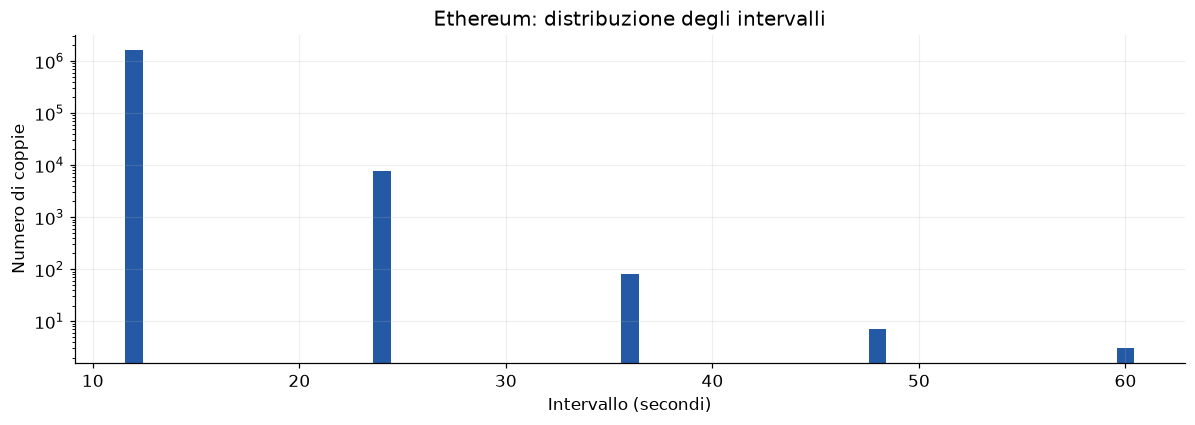

In [11]:
df["block_interval"] = pd.Series(df["timestamp"].to_numpy(), dtype="Int64").diff()
intervals = df["block_interval"].dropna().astype("int64")
median_interval = float(intervals.median())
mad = float((intervals - median_interval).abs().median())
q1, q3 = intervals.quantile([0.25, 0.75])
iqr = float(q3 - q1)
if mad > 0:
    long_interval_threshold = median_interval + 3.5 * mad / 0.6745
    interval_method = "MAD: sola coda superiore"
elif iqr > 0:
    long_interval_threshold = float(q3 + 1.5 * iqr)
    interval_method = "IQR: sola coda superiore (MAD nulla)"
else:
    long_interval_threshold = float(intervals.quantile(0.999))
    interval_method = "Quantile 99,9% (MAD e IQR nulli)"
df["interval_anomaly"] = (
    (df["block_interval"] <= 0) | (df["block_interval"] > long_interval_threshold)
).fillna(False)
print("Metodo:", interval_method)
print("Soglia superiore (secondi):", long_interval_threshold)
print("Intervalli segnalati:", int(df["interval_anomaly"].sum()))
display(intervals.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).to_frame())
display(df.loc[df["interval_anomaly"], ["block_number", "timestamp", "block_interval"]].head(10))

fig, ax = plt.subplots()
interval_counts = intervals.value_counts().sort_index()
ax.bar(interval_counts.index, interval_counts.values, color=COLOR, width=0.85)
ax.set(
    title=f"{CHAIN_LABEL}: distribuzione degli intervalli",
    xlabel="Intervallo (secondi)",
    ylabel="Numero di coppie",
)
ax.set_yscale("log")  # Rendiamo leggibili anche gli intervalli rari.
fig.tight_layout()
plt.show()
plt.close(fig)

## Unità delle fee e utilizzo del gas

Convertiamo wei/gas in gwei/gas dividendo per 10⁹, mantenendo gli originali.
Distinguiamo la quota del gas limit dall’utilizzo relativo al target intero del protocollo.

In [12]:
df["gas_utilization"] = df["gas_used"] / df["gas_limit"]
# Riferimento esplicito: per Polygon non identifica il target di ogni produttore.
reference_targets = (
    df["gas_limit"] // 2 if CHAIN == "ethereum" else df["gas_limit"] * TARGET_PERCENTAGE // 100
)
df["target_utilization"] = df["gas_used"] / reference_targets
for source, target in zip(
    fee_columns, ["base_fee_gwei", "priority_fee_p50_gwei", "priority_fee_p90_gwei"], strict=True
):
    df[target] = df[source] / 1e9

## Definizione teorica dell’utilizzo

Confrontiamo X con il target intero usato dal protocollo.
Quantifichiamo la differenza per limiti dispari e verifichiamo il supporto [0, 2].

In [13]:
df["X"] = 2 * df["gas_used"] / df["gas_limit"]
odd_gas_limit = (
    df["gas_limit"].mod(2).eq(1)
)  # Identifica i limiti dispari, per confrontare le due definizioni di utilizzo.
utilization_difference = df["target_utilization"] - df["X"]

assert df["X"].between(0, 2).all(), "Valori di X fuori dall'intervallo [0, 2]"

display(
    pd.Series(
        {
            "Blocchi con gas limit dispari": int(odd_gas_limit.sum()),
            "Massima differenza assoluta tra target_utilization e X": float(
                utilization_difference.abs().max()
            ),
        },
        name="Confronto delle definizioni",
    ).to_frame()
)

,Confronto delle definizioni
Blocchi con gas limit dispari,1.814700e+05
Massima differenza assoluta tra target_utilization e X,3.352746e-08


## Log delle fee in wei/gas

log1p conserva le priority fee nulle e riduce l’escursione della scala.
Il log della base fee è un livello trasformato, distinto dal suo log return.

In [14]:
for column in fee_columns:
    df[f"log_{column}"] = np.log1p(df[column])

## Dispersione fra p90 e p50

Misuriamo la distanza fra i log delle priority fee incluse.
La dispersione non negativa descrive una distribuzione interna al blocco, non un’innovazione.

In [15]:
df["priority_fee_dispersion"] = (
    df["log_effective_priority_fee_per_gas_p90"] - df["log_effective_priority_fee_per_gas_p50"]
)

## Log return della base fee

Calcoliamo log(B[n+1]/B[n]) per tutte le coppie osservate.
L’ultima riga resta assente e il valore è un esito verso il successore, non un predittore disponibile a n.

In [16]:
df["base_log_fee_return"] = np.log(df["base_fee_per_gas"].shift(-1) / df["base_fee_per_gas"])

## Intervallo verso il successore

Allineiamo timestamp[n+1]−timestamp[n] alla convenzione teorica.
La misura all’indietro resta separata; il successore esterno al campione non viene inventato.

In [17]:
df["block_interval_next"] = df["block_interval"].shift(-1)

## Prime differenze di utilizzo e log fee

Costruiamo variazioni all’indietro fra blocchi consecutivi già chiusi.
Le innovazioni rispetto alla media condizionata vengono stimate nello step 5.

In [18]:
df["delta_X"] = df["X"].diff()
df["delta_log_p90"] = df["log_effective_priority_fee_per_gas_p90"].diff()
df["delta_log_p50"] = df["log_effective_priority_fee_per_gas_p50"].diff()

## Allineamento e assenze ai bordi

Verifichiamo identità numeriche e posizione dei valori mancanti strutturali.
La prima o ultima osservazione non viene riempita con zero.

In [19]:
assert df["priority_fee_dispersion"].ge(0).all()

np.testing.assert_allclose(
    df["block_interval_next"].iloc[:-1].astype(float), df["block_interval"].iloc[1:].astype(float)
)

np.testing.assert_allclose(
    df["base_log_fee_return"].iloc[:-1],
    np.log(df["base_fee_per_gas"]).diff().iloc[1:],
    rtol=0,
    atol=1e-12,
)

expected_missing = {
    "block_interval": 1,
    "base_log_fee_return": 1,
    "block_interval_next": 1,
    "delta_X": 1,
    "delta_log_p50": 1,
    "delta_log_p90": 1,
}

derived_missing = df.drop(columns=list(RAW_COLUMNS)).isna().sum()

assert derived_missing[derived_missing.gt(0)].to_dict() == expected_missing

assert df[["block_interval", "delta_X", "delta_log_p50", "delta_log_p90"]].iloc[0].isna().all()

assert df[["base_log_fee_return", "block_interval_next"]].iloc[-1].isna().all()

display(derived_missing[derived_missing.gt(0)].rename("valori mancanti strutturali").to_frame())

,valori mancanti strutturali
block_interval,1
base_log_fee_return,1
block_interval_next,1
delta_X,1
delta_log_p90,1
delta_log_p50,1


## Audit degli estremi

Le soglie IQR segnalano valori da esaminare, senza classificarli come errori.
Verifichiamo anche la convenzione delle priority fee nei blocchi vuoti.

In [20]:
audit_columns = fee_columns + ["gas_used", "gas_limit", "tx_count"]
audit_rows = []
for column in audit_columns:
    values = df[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)
    audit_rows.append(
        {
            "column": column,
            "min": int(values.min()),
            "max": int(values.max()),
            "iqr": float(iqr),
            "lower_threshold": float(lower),
            "upper_threshold": float(upper),
            "flagged_count": int(flagged.sum()),
            "flagged_percentage": float(flagged.mean() * 100),
        }
    )

extreme_audit = pd.DataFrame(audit_rows)
display(extreme_audit)
empty_blocks = df["tx_count"].eq(0)
assert df["gas_used"].eq(0).equals(empty_blocks)
assert df.loc[empty_blocks, fee_columns[1:]].eq(0).all().all()

print("Blocchi vuoti conservati: ", int(empty_blocks.sum()))

,column,min,max,iqr,lower_threshold,upper_threshold,flagged_count,flagged_percentage
0,base_fee_per_gas,8703865,49746017199,1.439420e+08,-1.674071e+08,4.083611e+08,172881,10.448911
1,effective_priority_fee_per_gas_p50,0,13491893322919,5.880157e+07,-8.582425e+07,1.493820e+08,212694,12.855205
2,effective_priority_fee_per_gas_p90,0,13491893322919,1.167554e+09,-9.188859e+08,3.751332e+09,77683,4.695153
3,gas_used,0,60090038,1.694331e+07,-4.268573e+06,6.350466e+07,0,0.000000
4,gas_limit,59358395,60117241,0.000000e+00,6.000000e+07,6.000000e+07,364129,22.007922
5,tx_count,0,2753,1.810000e+02,-8.250000e+01,6.415000e+02,89382,5.402240


Blocchi vuoti conservati:  653


## Campione mirato di blocchi estremi

Selezioniamo minimi, massimi e la coppia con intervallo più lungo.
Il campione serve al riscontro esterno e non rappresenta tutta la popolazione.

In [21]:
review_indices = {df[column].idxmin() for column in audit_columns}
review_indices.update(df[column].idxmax() for column in audit_columns)

longest_interval_index = df["block_interval"].idxmax()
review_indices.update([longest_interval_index - 1, longest_interval_index])

review = df.loc[sorted(review_indices), list(RAW_COLUMNS)].copy()

display(review)

,block_number,timestamp,base_fee_per_gas,gas_used,gas_limit,tx_count,effective_priority_fee_per_gas_p50,effective_priority_fee_per_gas_p90
27,23935721,1764798947,20682053,59977650,60000000,492,0,14052467
500,23936194,1764804995,23409374,0,59999943,0,0,0
1582,23937276,1764819023,18202000,5946376,59941294,107,79000000,2000000000
1583,23937277,1764819083,16378175,45663103,59999829,625,2108713,1983621825
1668,23937362,1764820559,8703865,59996371,59999943,1084,2407245,1991296135
5654,23941348,1764871775,51581300,38975258,59358395,404,16845110,2000000000
45077,23980771,1765350983,162753040,58658045,60117241,175,2000000,100000000
194599,24130293,1767156167,40939342,59994096,60000000,2753,959060658,959060658
458491,24394185,1770337451,49746017199,24507913,60000000,74,4741990063,9748163291
807793,24743487,1774549259,134218713,4911216,60000000,12,13491893322919,13491893322919


## Contesto del picco di priority fee

Confrontiamo il massimo p50 con i due blocchi precedenti e successivi.
Gas e numero di transazioni aiutano a distinguere congestione e singolo evento estremo.

In [22]:
peak_index = df["effective_priority_fee_per_gas_p50"].idxmax()

display(
    df.loc[
        peak_index - 2 : peak_index + 2,
        ["block_number", "gas_used", "tx_count", "priority_fee_p50_gwei", "priority_fee_p90_gwei"],
    ]
)

,block_number,gas_used,tx_count,priority_fee_p50_gwei,priority_fee_p90_gwei
807791,24743485,37620281,185,0.165205,2.000000
807792,24743486,36226367,222,0.015823,2.869175
807793,24743487,4911216,12,13491.893323,13491.893323
807794,24743488,31590086,334,0.530835,2.006592
807795,24743489,59931858,240,0.016299,0.456102


## Percentili ponderati e lettore RPC

Definiamo il riscontro di header e ricevute e ricostruiamo i percentili pesati per gas.
Due esempi controllano i blocchi vuoti e una distribuzione con pesi diversi.

In [23]:
from urllib.request import Request, urlopen

RPC_URL = "https://ethereum-rpc.publicnode.com"


def rpc(method, params):
    request = Request(
        RPC_URL,
        data=json.dumps({"jsonrpc": "2.0", "id": 1, "method": method, "params": params}).encode(),
        headers={"Content-Type": "application/json"},
    )

    with urlopen(request, timeout=15) as response:
        payload = json.load(response)

    if "error" in payload:
        raise RuntimeError(str(payload["error"]))
    if payload.get("result") is None:
        raise ValueError("Il servizio RPC non ha restituito dati")

    return payload["result"]


def priority_percentiles(receipts, base_fee):
    if not receipts:
        return [0, 0]

    tips = np.array(
        [int(receipt["effectiveGasPrice"], 16) - base_fee for receipt in receipts], dtype=np.int64
    )

    gas = np.array([int(receipt["gasUsed"], 16) for receipt in receipts], dtype=np.int64)

    assert (tips >= 0).all() and (gas > 0).all()

    order = np.argsort(tips, kind="stable")
    cumulative_gas = gas[order].cumsum()

    thresholds = [int(cumulative_gas[-1]) * percentile // 100 for percentile in [50, 90]]
    positions = np.searchsorted(cumulative_gas, thresholds, side="left")

    return tips[order][positions].tolist()


assert priority_percentiles([], 100) == [0, 0]

assert priority_percentiles(
    [
        {"effectiveGasPrice": hex(110), "gasUsed": hex(80)},
        {"effectiveGasPrice": hex(200), "gasUsed": hex(20)},
    ],
    100,
) == [10, 100]

## Riscontro esterno degli estremi

Rileggiamo i valori RPC salvati e li riconciliamo con il dataset verificato.
Con REFRESH_RPC=True si ritentano soltanto i blocchi senza una risposta valida.

In [24]:
cached_path = output_directory / "extreme_rpc_review.csv"
summary_path = output_directory / "preprocessing_summary.json"
previous_summary = json.loads(summary_path.read_text()) if summary_path.exists() else {}
cached = pd.read_csv(cached_path).fillna("") if cached_path.exists() else pd.DataFrame()
if not cached.empty:
    assert previous_summary.get("dataset_sha256") == manifest["output"]["sha256"]
    assert not cached["block_number"].duplicated().any()
    # Una conferma salvata è riusabile solo se tutti i valori remoti coincidono ancora.
    for row in cached.loc[cached["status"].eq("confermato")].itertuples():
        remote = json.loads(row.rpc_values)
        local = df.loc[df["block_number"].eq(row.block_number)].iloc[0]
        assert all(int(local[column]) == remote[column] for column in RAW_COLUMNS)
if REFRESH_RPC:
    assert int(rpc("eth_chainId", []), 16) == EXPECTED_CHAIN_ID

header_fields = {
    "block_number": "number",
    "timestamp": "timestamp",
    "base_fee_per_gas": "baseFeePerGas",
    "gas_used": "gasUsed",
    "gas_limit": "gasLimit",
}

rpc_records = []

for row in review.itertuples(index=False):
    number = int(row.block_number)
    previous = cached.loc[cached["block_number"].eq(number)] if not cached.empty else cached
    if not previous.empty and (previous.iloc[0]["status"] != "non_verificato" or not REFRESH_RPC):
        rpc_records.append(previous.iloc[0].to_dict())
        continue
    record = {"block_number": number}
    if not REFRESH_RPC:
        record.update(
            status="non_verificato", detail="Nessun riscontro salvato; impostare REFRESH_RPC=True"
        )
        rpc_records.append(record)
        continue

    try:
        block = rpc("eth_getBlockByNumber", [hex(number), False])
        receipts = rpc("eth_getBlockReceipts", [hex(number)])

        assert len(receipts) == len(block["transactions"])
        assert {receipt["transactionHash"] for receipt in receipts} == set(block["transactions"])
        assert all(receipt["blockHash"] == block["hash"] for receipt in receipts)
        assert sum(int(receipt["gasUsed"], 16) for receipt in receipts) == int(block["gasUsed"], 16)

        remote = {column: int(block[field], 16) for column, field in header_fields.items()}
        remote["tx_count"] = len(block["transactions"])

        p50, p90 = priority_percentiles(receipts, remote["base_fee_per_gas"])
        remote["effective_priority_fee_per_gas_p50"] = p50
        remote["effective_priority_fee_per_gas_p90"] = p90

        differences = [
            column for column in RAW_COLUMNS if int(getattr(row, column)) != remote[column]
        ]

        record.update(
            {
                "status": "discordante" if differences else "confermato",
                "detail": ", ".join(differences),
                "block_hash": block["hash"],
                "rpc_values": json.dumps(remote, sort_keys=True),
            }
        )

    except Exception as error:
        record.update({"status": "non_verificato", "detail": f"{type(error).__name__}: {error}"})

    rpc_records.append(record)

rpc_review = pd.DataFrame(rpc_records)
rpc_checked_at = (
    pd.Timestamp.now(tz="UTC").isoformat()
    if REFRESH_RPC
    else previous_summary.get("rpc_review_checked_at")
)
print("Riscontri RPC:", "aggiornati" if REFRESH_RPC else "cache, non una verifica di rete odierna")

display(rpc_review[["block_number", "status", "detail"]])

Riscontri RPC: cache, non una verifica di rete odierna


,block_number,status,detail
0,23935721,confermato,
1,23936194,confermato,
2,23937276,non_verificato,ValueError: Il servizio RPC non ha restituito ...
3,23937277,non_verificato,ValueError: Il servizio RPC non ha restituito ...
4,23937362,confermato,
5,23941348,confermato,
6,23980771,confermato,
7,24130293,confermato,
8,24394185,confermato,
9,24743487,non_verificato,ValueError: Il servizio RPC non ha restituito ...


## Intervalli e slot intermedi

Contiamo gli intervalli per durata e gli slot intermedi senza blocco canonico.
Un intervallo lungo non equivale a un numero di blocco mancante e non ne prova la causa.

In [25]:
intervals = df["block_interval"].dropna().astype("int64")

assert intervals.gt(0).all()
assert intervals.mod(12).eq(0).all()

interval_table = intervals.value_counts().sort_index().rename_axis("seconds").to_frame("pairs")
interval_table["percentage"] = 100 * interval_table["pairs"] / len(intervals)

display(interval_table)

print("Intervalli oltre 12 secondi:", int(intervals.gt(12).sum()))
print("Intervalli oltre 24 secondi:", int(intervals.gt(24).sum()))
print("Slot intermedi senza blocchi canonici:", int((intervals // 12 - 1).sum()))

,pairs,percentage
seconds,,
12,1646808,99.532981
24,7635,0.461459
36,82,0.004956
48,7,0.000423
60,3,0.000181


Intervalli oltre 12 secondi: 7727
Intervalli oltre 24 secondi: 92
Slot intermedi senza blocchi canonici: 7832


## Deadline in blocchi e in secondi

Misuriamo il tempo di cinque transizioni per tutte le finestre complete.
Il confronto con sessanta secondi quantifica quanto le due scadenze differiscano nel campione.

In [26]:
K = 5
DEADLINE_SECONDS = 60

durations = (df["timestamp"].shift(-K) - df["timestamp"]).dropna()

deadline_report = pd.Series(
    {
        "orizzonte_blocchi": K,
        "deadline_secondi": DEADLINE_SECONDS,
        "finestre_complete": len(durations),
        "durata_media_secondi": float(durations.mean()),
        "durata_mediana_secondi": float(durations.median()),
        "durata_p99_secondi": float(durations.quantile(0.99)),
        "durata_massima_secondi": float(durations.max()),
        "finestre_oltre_deadline_pct": float(100 * durations.gt(DEADLINE_SECONDS).mean()),
    },
    name="Scenario temporale",
)

display(deadline_report.to_frame())

,Scenario temporale
orizzonte_blocchi,5.000000e+00
deadline_secondi,6.000000e+01
finestre_complete,1.654531e+06
durata_media_secondi,6.028401e+01
durata_mediana_secondi,6.000000e+01
durata_p99_secondi,7.200000e+01
durata_massima_secondi,1.680000e+02
finestre_oltre_deadline_pct,2.284273e+00


## Conclusione sulla qualità

Riepiloghiamo copertura, unità, allineamento e casi ancora non verificati.
Nessuna osservazione viene esclusa sulla sola base delle diagnostiche descrittive.

In [27]:
rpc_counts = rpc_review["status"].value_counts().to_dict()

quality_conclusion = (
    f"Il dataset contiene {len(df):,} blocchi consecutivi. "
    "Non sono emerse violazioni nei controlli di integrità eseguiti. "
    "Le fee originali sono in wei/gas; le conversioni descrittive "
    "sono in gwei/gas e i log1p usano i valori in wei/gas. "
    "X segue la definizione teorica; target_utilization mantiene "
    "il denominatore intero del protocollo. "
    "block_interval guarda al predecessore, mentre "
    "block_interval_next e il log return guardano al successore. "
    "I sei valori mancanti derivati sono esclusivamente ai bordi "
    "del campione. "
    f"Sui {len(review)} blocchi selezionati per il riscontro RPC: "
    f"{rpc_counts.get('confermato', 0)} confermati, "
    f"{rpc_counts.get('discordante', 0)} discordanti e "
    f"{rpc_counts.get('non_verificato', 0)} non verificati. "
    "Il riscontro esterno riguarda un campione mirato. "
    "I segnali IQR non sono trattati automaticamente come errori. "
    f"Sono conservati anche i {int(empty_blocks.sum())} blocchi vuoti, "
    "con percentili nulli secondo la convenzione della fonte. "
    "Nessuna riga è stata esclusa, interpolata o sottoposta "
    "a winsorization. "
    "Gli intervalli lunghi sono conservati e la durata di un "
    "orizzonte in blocchi è distinta da una deadline in secondi."
)

print(quality_conclusion)

Il dataset contiene 1,654,536 blocchi consecutivi. Non sono emerse violazioni nei controlli di integrità eseguiti. Le fee originali sono in wei/gas; le conversioni descrittive sono in gwei/gas e i log1p usano i valori in wei/gas. X segue la definizione teorica; target_utilization mantiene il denominatore intero del protocollo. block_interval guarda al predecessore, mentre block_interval_next e il log return guardano al successore. I sei valori mancanti derivati sono esclusivamente ai bordi del campione. Sui 11 blocchi selezionati per il riscontro RPC: 7 confermati, 0 discordanti e 4 non verificati. Il riscontro esterno riguarda un campione mirato. I segnali IQR non sono trattati automaticamente come errori. Sono conservati anche i 653 blocchi vuoti, con percentili nulli secondo la convenzione della fonte. Nessuna riga è stata esclusa, interpolata o sottoposta a winsorization. Gli intervalli lunghi sono conservati e la durata di un orizzonte in blocchi è distinta da una deadline in seco

## Riepilogo e salvataggio del preprocessing

Salviamo dati preparati e report con identità della fonte, convenzioni e qualità osservata.
Le assenze derivate sono distinte dagli errori originali; ogni step successivo rilegge questi artefatti.

In [28]:
report = pd.Series(
    {
        **integrity_checks,
        "Intervalli segnalati (diagnostica descrittiva)": int(df["interval_anomaly"].sum()),
    },
    name="Conteggio",
)
display(report.to_frame())
display(
    df.drop(columns=list(RAW_COLUMNS))
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .rename("Assenze nelle colonne derivate")
    .to_frame()
)
complete_range = (
    gap_count == unordered_pairs == duplicated_blocks == 0
    and len(df) == dataset.last_block - dataset.first_block + 1
)
preprocessing_summary = {
    "chain": CHAIN,
    "chain_id": dataset.chain_id,
    "dataset_id": DATASET_ID,
    "source_doi": "10.5281/zenodo.22094893",
    "dataset_sha256": manifest["output"]["sha256"],
    "rows": len(df),
    "first_block": dataset.first_block,
    "last_block": dataset.last_block,
    "complete_range": bool(complete_range),
    "raw_columns": list(RAW_COLUMNS),
    "integrity_checks": integrity_checks,
    "raw_missing_values": raw_missing_count,
    "derived_missing_values": int(df.drop(columns=list(RAW_COLUMNS)).isna().sum().sum()),
    "block_interval_convention": "timestamp[n] - timestamp[n-1]",
}
assert not rpc_review["status"].eq("discordante").any(), (
    "Risolvere le discordanze RPC prima di esportare il preprocessing."
)
assert len(df) == dataset.row_count

preprocessing_summary.update(
    {
        "fee_log_reference_unit": "wei/gas",
        "theoretical_utilization_definition": "2 * gas_used / gas_limit",
        "protocol_utilization_definition": "gas_used / (gas_limit // 2)",
        "odd_gas_limit_rows": int(odd_gas_limit.sum()),
        "block_interval_next_convention": "timestamp[n+1] - timestamp[n]",
        "base_fee_log_return_definition": "log(B[n+1] / B[n])",
        "first_differences_convention": "value[n] - value[n-1]",
        "derived_missing_by_column": (derived_missing[derived_missing.gt(0)].astype(int).to_dict()),
        "empty_blocks": int(empty_blocks.sum()),
        "excluded_rows": 0,
        "extreme_observation_policy": ("Keep all rows; IQR flags alone do not justify exclusion"),
        "rpc_review_url": RPC_URL,
        "rpc_review_checked_at": rpc_checked_at,
        "rpc_review_selection": (
            "First minimum and maximum of each audited variable, "
            "plus one pair with the longest block interval"
        ),
        "rpc_review_counts": rpc_counts,
        "quality_conclusion": quality_conclusion,
    }
)

extreme_audit.to_csv(output_directory / "extreme_audit.csv", index=False)
review.to_csv(output_directory / "extreme_review_sample.csv", index=False)
rpc_review.to_csv(output_directory / "extreme_rpc_review.csv", index=False)
interval_table.to_csv(output_directory / "block_interval_report.csv")
deadline_report.to_csv(output_directory / "deadline_scenario.csv")
report.to_csv(output_directory / "preprocessing_report.csv")
(output_directory / "preprocessing_summary.json").write_text(
    json.dumps(preprocessing_summary, indent=2) + "\n"
)
if EXPORT_DIAGNOSTICS:
    df.to_parquet(output_directory / f"{CHAIN}_blocks_diagnostics.parquet", index=False)
print("Intervallo completo:", complete_range)
print("Risultati step 1 salvati in:", output_directory)

,Conteggio
Blocchi duplicati,0
Righe originali duplicate,0
Coppie non ordinate,0
Interruzioni della sequenza,0
Blocchi mancanti,0
Valori mancanti nelle colonne originali,0
Timestamp non crescenti,0
Osservazioni gas non valide,0
Base fee non positive,0
Priority fee negative,0


,Assenze nelle colonne derivate
block_interval,1
base_log_fee_return,1
block_interval_next,1
delta_X,1
delta_log_p90,1
delta_log_p50,1


Intervallo completo: True
Risultati step 1 salvati in: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step1
